In [8]:
%matplotlib inline
import numpy as np
from matplotlib_inline import backend_inline
from d2l import torch as d2l

In [18]:
def f(x):
    return np.sin(x)

In [3]:
def use_svg_display():  #@save
    backend_inline.set_matplotlib_formats('svg')

以上代码使用svg矢量图在jupyter中展示，而不会影响全局matplotlib环境

In [4]:
def set_figsize(figsize=(3.5, 2.5)):  #@save
    use_svg_display()
    d2l.plt.rcParams['figure.figsize'] = figsize

In [9]:
#@save
def set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend):
    axes.set_xlabel(xlabel)
    axes.set_ylabel(ylabel)
    axes.set_xscale(xscale)
    axes.set_yscale(yscale)
    axes.set_xlim(xlim)
    axes.set_ylim(ylim)
    if legend:
        axes.legend(legend)
    axes.grid()

In [12]:
#@save
def plot(X, Y=None, xlabel=None, ylabel=None, legend=None, xlim=None, ylim=None, xscale='linear', yscale='linear', fmts=('-', 'm--', 'g-', 'r:'), figsize=(3.5, 2.5), axes=None):
    if legend is None:
        legend = []
    set_figsize(figsize)
    axes = axes if axes else d2l.plt.gca()

    # 判断 X（张量或列表）是否只有一维
    def has_one_axis(X):
        return (hasattr(X, "ndim") and X.ndim == 1 or isinstance(X, list) and not hasattr(X[0], "__len__"))

    if has_one_axis(X):
        X = [X]
    if Y is None:
        X, Y = [[]] * len(X), X
    elif has_one_axis(Y):
        Y = [Y]
    if len(X) != len(Y):
        X = X * len(Y)
    axes.cla()
    for x, y, fmt in zip(X, Y, fmts):
        if len(x):
            axes.plot(x, y, fmt)
        else:
            axes.plot(y, fmt)
    set_axes(axes, xlabel, ylabel, xlim, ylim, xscale, yscale, legend)

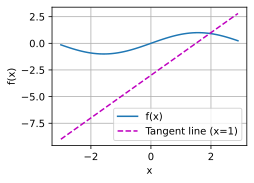

In [24]:
x = np.arange(-3, 3, 0.1)
plot(x, [f(x), 2 * x - 3], 'x', 'f(x)', legend=['f(x)', 'Tangent line (x=1)'])

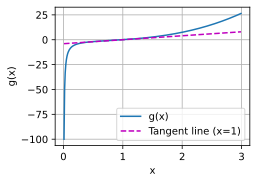

In [30]:
def g(x):
    return x**3 - 1/x

m = np.arange(0.01, 3, 0.01)
plot(m, [g(m), m * 4 - 4], 'x', 'g(x)', legend=['g(x)', 'Tangent line (x=1)'])